[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_RQI_Mosaic_SpatialBias_DualPol/blob/main/notebooks/03_zr_and_dualpol_qpe.ipynb)

# 03 · การประมาณฝน: Z–R และ dual-polarization
*Rain-rate estimation: Z–R relations and polarimetric estimators*

| | |
|---|---|
| **ระดับ** | 🟢 ป.ตรี ปี 3–4 และ 🔵 ป.โท |
| **เวลาโดยประมาณ** | 90–120 นาที |
| **ควรผ่านมาก่อน** | 01 |
| **ข้อมูลเข้า** | UF เรดาร์แม่ฮ่องสอน (MHS) 10:00 UTC (ฝนพาความร้อน) |
| **ผลลัพธ์** | แผนที่ฝน 4 วิธี, แผนที่แหล่งที่มาของค่า (Z/A/KDP), กราฟเปรียบเทียบ, ตารางสรุป |

> 📌 **วิธีใช้:** กด *Runtime ▸ Run all* ได้ทันที หรือรันทีละเซลล์ (Shift+Enter) พร้อมอ่านคำอธิบาย
> เซลล์ที่มีหัวข้อ 🔑 เป็นเฉลยที่ซ่อนไว้ ลองทำแบบฝึกหัดก่อนแล้วค่อยเปิดดู

## 🎯 วัตถุประสงค์การเรียนรู้
1. **อธิบาย** ที่มาของความสัมพันธ์ Z–R จากการกระจายขนาดเม็ดฝน (DSD) และสาเหตุที่ไม่มีสูตรเดียวใช้ได้ทุกที่
2. **คำนวณ** ฝนจาก Z ด้วยสูตร Marshall–Palmer และ Rosenfeld และจากตัวแปร dual-pol R(KDP), R(A)
3. **ประกอบ** ตัวประมาณแบบผสม (blended) ตามเงื่อนไขความเข้มฝนและคุณภาพเฟส
4. **ประเมิน** ความไวของแต่ละวิธีต่อความคลาดเคลื่อนการปรับเทียบ Z

## 1. หลักการ
### 1.1 จาก DSD สู่ Z และ R
ถ้า $N(D)$ คือจำนวนเม็ดฝนต่อปริมาตรต่อช่วงเส้นผ่านศูนย์กลาง (m⁻³ mm⁻¹) และ $v(D)$ คือความเร็วตกของเม็ดฝน

$$Z = \int_0^\infty N(D)\,D^6\,dD, \qquad R = 0.6\pi\times10^{-3}\int_0^\infty N(D)\,D^3\,v(D)\,dD \;\;[\text{mm h}^{-1}]$$

Marshall & Palmer (1948) พบว่า $N(D) = N_0 e^{-\Lambda D}$, $N_0 = 8000$ m⁻³ mm⁻¹, $\Lambda = 4.1R^{-0.21}$ mm⁻¹ → ได้ $Z = aR^b$
**ค่า a, b เปลี่ยนตามชนิดฝน** เพราะ DSD เปลี่ยน:

| ความสัมพันธ์ | a | b | เหมาะกับ |
|---|---|---|---|
| Marshall–Palmer (1948) | 200 | 1.6 | ฝนแบบ stratiform ละติจูดกลาง |
| WSR-88D convective (Fulton et al. 1998) | 300 | 1.4 | ฝนพาความร้อน สหรัฐฯ |
| Rosenfeld tropical (1993) | 250 | 1.2 | ฝนเขตร้อน เม็ดเล็กจำนวนมาก |

ผกผัน: $R = (Z/a)^{1/b}$ โดย $Z$ ต้องอยู่ในหน่วยเชิงเส้น mm⁶ m⁻³ ($Z = 10^{\text{dBZ}/10}$)

### 1.2 ตัวประมาณ dual-pol
$$R(K_{DP}) = c\,K_{DP}^{\,d}\quad(c\approx 29.7,\ d\approx0.85\ \text{ที่ย่าน C}), \qquad R(A) = c\,A^{d}\quad(c\approx250,\ d\approx0.91)$$

- $K_{DP}$ และ $A$ แปรผันเกือบเชิงเส้นกับปริมาณน้ำ ($\propto D^{4\text{–}5}$) จึงไวต่อ DSD น้อยกว่า Z ($\propto D^6$)
- มาจาก **เฟส** → ไม่ขึ้นกับการปรับเทียบ Z การลดทอน และการบังลำคลื่นบางส่วน
- แต่มีสัญญาณรบกวนสูงในฝนเบา จึงใช้แบบผสม (blended):
  - $R(K_{DP})$ ถ้า Z ≥ 40 dBZ และ KDP ≥ 0.3 °/km (ฝนหนัก)
  - $R(A)$ ถ้า ΔΦDP ตาม ray ≥ 5° และ Z ≥ 25 dBZ (ฝนปานกลาง)
  - $R(Z)$ นอกนั้น (ฝนเบา)

In [1]:
PACKAGES = ('teaching_data', 'products')
#@title ⚙️ เตรียมสภาพแวดล้อม (รันเซลล์นี้ก่อนทุกครั้ง) { display-mode: "form" }
import os, sys, subprocess
REPO, OWNER = "Teach_RQI_Mosaic_SpatialBias_DualPol", "nattaponm"
if "google.colab" in sys.modules:
    if not os.path.exists(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        f"https://github.com/{OWNER}/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
else:  # running on your own computer: move to the repository root
    while not os.path.exists("config/study_area.yaml") and os.getcwd() != os.path.dirname(os.getcwd()):
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
from radteach import colab
P = colab.setup(packages=PACKAGES)

installing: arm_pyart (about 1–2 minutes the first time) …
downloading teaching_data_v1.zip …
teaching_data_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
downloading teaching_products_v1.zip …
teaching_products_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
repository : /content/Teach_RQI_Mosaic_SpatialBias_DualPol
Colab      : True
Thai font  : Sarabun
data       : /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw


## 2. ทดลอง: สร้าง Z–R จาก DSD แบบ Marshall–Palmer

Z = 238 R^1.49  (จาก DSD แบบ MP + ความเร็วตก Atlas–Ulbrich)


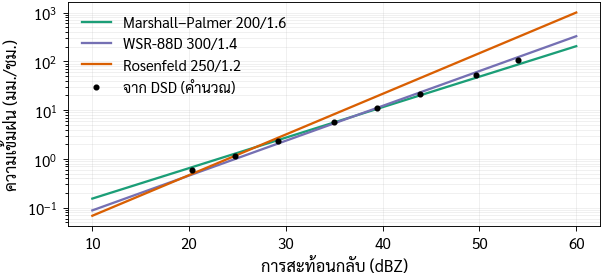

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
trapz = getattr(np, "trapezoid", None) or np.trapz      # NumPy ≥ 2.0 / < 2.0
from radteach import io, qc, qpe, plotting as pl, mapping as mp
D = np.linspace(0.1, 8, 400)                         # mm
v = 3.78 * D ** 0.67                                  # m/s (Atlas & Ulbrich 1977)
rows = []
for R in [0.5, 1, 2, 5, 10, 20, 50, 100]:
    lam = 4.1 * R ** -0.21; N = 8000 * np.exp(-lam * D)
    rows.append(dict(R_input=R, Z=trapz(N * D ** 6, D), R_dsd=0.6e-3 * np.pi * trapz(N * D ** 3 * v, D)))
dsd = pd.DataFrame(rows)
b, loga = np.polyfit(np.log10(dsd.R_dsd), np.log10(dsd.Z), 1)
print(f"Z = {10**loga:.0f} R^{b:.2f}  (จาก DSD แบบ MP + ความเร็วตก Atlas–Ulbrich)")
dbz = np.linspace(10, 60, 101)
fig, ax = pl.subplots(width="one_half", height_mm=65)
for name, (a_, b_), c in [("Marshall–Palmer 200/1.6", (200, 1.6), "#1b9e77"), ("WSR-88D 300/1.4", (300, 1.4), "#7570b3"),
                          ("Rosenfeld 250/1.2", (250, 1.2), "#d95f02")]:
    ax.semilogy(dbz, qpe.r_from_z(dbz, a_, b_, cap_dbz=60), color=c, label=name)
ax.semilogy(10 * np.log10(dsd.Z), dsd.R_dsd, "ko", ms=3, label="จาก DSD (คำนวณ)")
ax.set_xlabel(pl.L("dbz")); ax.set_ylabel(pl.L("rain_mmh")); ax.grid(alpha=0.3, which="both", lw=0.4); ax.legend()
pl.save(fig, "03_zr_relations"); plt.show()

**สังเกต:** ที่ 50 dBZ สูตร Rosenfeld ให้ฝนมากกว่า Marshall–Palmer หลายเท่า — การเลือกสูตรผิดสร้างความคลาดเคลื่อนได้มากกว่า 100%

## 3. ข้อมูลจริง: เรดาร์แม่ฮ่องสอน (MHS) 10:00 UTC
ชั่วโมงนี้มีฝนพาความร้อนรุนแรงในพื้นที่สาละวินและแม่ฮ่องสอน และ MHS มีคุณภาพเฟสดีที่สุดในเครือข่าย (notebook 01)
ใช้ค่าปรับเทียบที่คำนวณไว้แล้วในชุดผลลัพธ์สำเร็จรูป

In [3]:
cal = pd.read_csv(P.products / "calibration_20241003_10UTC.csv", index_col=0)
scans = io.list_scans(P.radar / "20241003_10UTC")
f = scans[(scans.radar == "MHS") & (scans.time == "2024-10-03 10:00")].path.iloc[0]
radar = io.read_radar(f)
c = cal.loc["MHS"]
sw, out = qc.process_sweep(radar, 0, c.zdr_offset_db, c.system_phase_deg, c.phidp_sign)
lonlat = mp.sweep_lonlat(sw)
lon0, lat0 = float(sw.longitude["data"][0]), float(sw.latitude["data"][0])
E = [lon0 - 0.75, lon0 + 0.55, lat0 - 0.35, lat0 + 0.75]   # ซูมเข้าหาพายุ
print(f"มุมยก {out['elev']:.1f}°, ใช้ R(KDP) {100*out['frac_kdp']:.1f}% และ R(A) {100*out['frac_a']:.1f}% ของ gate ฝน")

มุมยก 3.0°, ใช้ R(KDP) 2.0% และ R(A) 23.5% ของ gate ฝน


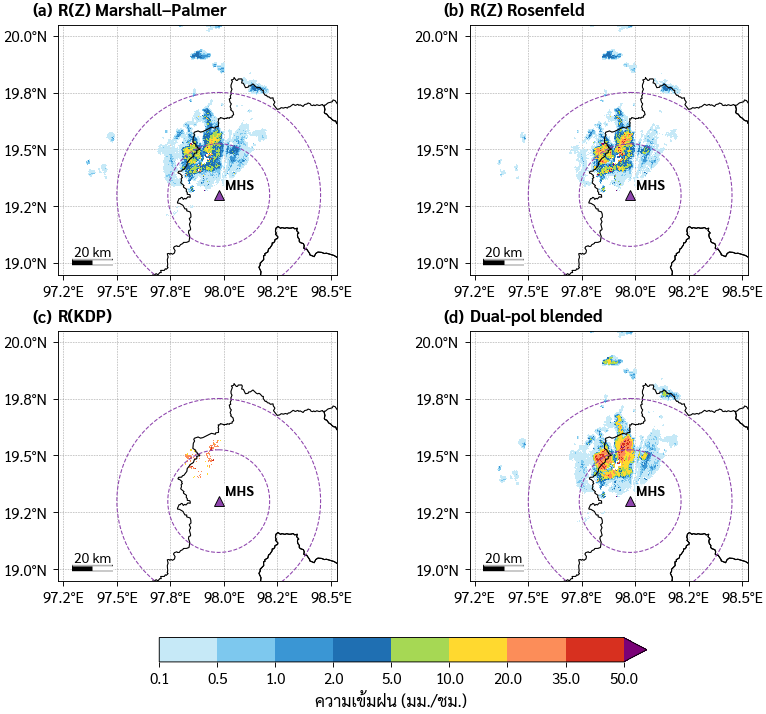

In [4]:
cm, nm = pl.rain_cmap()
panels = [("R(Z) Marshall–Palmer", out["R_MP"]), ("R(Z) Rosenfeld", out["R_ROS"]),
          ("R(KDP)", np.where(out["src"] == 2, out["R_KDP"], np.nan)), ("Dual-pol blended", out["R_DP"])]
fig, axs = pl.subplots(2, 2, width="double", height_mm=165)
for ax, (t, a) in zip(axs.ravel(), panels):
    im = mp.ppi(ax, sw, a, cm, nm, lonlat=lonlat)
    mp.basemap(ax, E, radars=["MHS"], rings_km=[25, 50], scale_km=20, north=False, title=t, lw=0.7, grid_step=0.25)
fig.colorbar(im, ax=axs, orientation="horizontal", shrink=0.6, extend="max").set_label(pl.L("rain_mmh"))
pl.panel_labels(axs); pl.save(fig, "03_mhs_four_estimators"); plt.show()

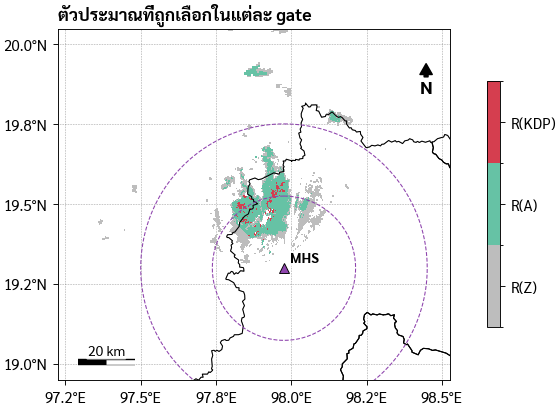

In [5]:
from matplotlib.colors import ListedColormap, BoundaryNorm
src = np.where(out["met"] & (out["R_MP"] >= 0.5), out["src"], np.nan)
fig, ax = pl.subplots(width="one_half", height_mm=95)
cms = ListedColormap(["#bdbdbd", "#66c2a5", "#d53e4f"])
im = mp.ppi(ax, sw, src, cms, BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), lonlat=lonlat)
mp.basemap(ax, E, radars=["MHS"], rings_km=[25, 50], scale_km=20, title="ตัวประมาณที่ถูกเลือกในแต่ละ gate", lw=0.7, grid_step=0.25)
cb = fig.colorbar(im, ax=ax, ticks=[0, 1, 2], shrink=0.7); cb.ax.set_yticklabels(["R(Z)", "R(A)", "R(KDP)"])
pl.save(fig, "03_mhs_estimator_source"); plt.show()

**แปลผล:** R(KDP) ถูกใช้เฉพาะแกนพายุ (Z ≥ 40 dBZ) R(A) ใช้ใน ray ที่มี ΔΦDP มากพอ ที่เหลือเป็น R(Z)
แผนที่นี้ช่วยให้เข้าใจว่า "dual-pol QPE" ไม่ได้แปลว่าใช้ KDP ทุกที่ แต่เป็นการเลือกตัวประมาณที่เหมาะกับสภาพฝน

## 4. เปรียบเทียบตัวประมาณในจุดเดียวกัน

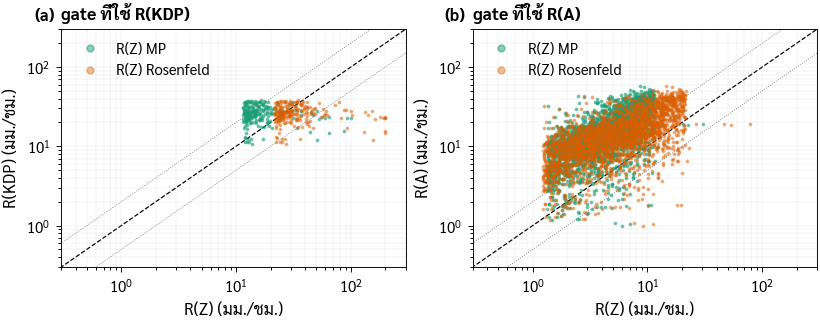

,พื้นที่ฝน ≥ 0.5 มม./ชม. (gate),เฉลี่ยในพื้นที่ฝน (มม./ชม.),สูงสุด (มม./ชม.)
R_MP,5147.0,3.76,99.85
R_ROS,4359.0,6.97,200.00
R_DP,5147.0,9.60,99.85


In [6]:
k = (out["src"] == 2)
a_ = (out["src"] == 1)
fig, axs = pl.subplots(1, 2, width="double", height_mm=75)
for ax, m, est, t in [(axs[0], k, "R_KDP", "gate ที่ใช้ R(KDP)"), (axs[1], a_, "R_A", "gate ที่ใช้ R(A)")]:
    ax.loglog(out["R_MP"][m], out[est][m], ".", ms=3, alpha=0.5, color="#1b9e77", label="R(Z) MP")
    ax.loglog(out["R_ROS"][m], out[est][m], ".", ms=3, alpha=0.4, color="#d95f02", label="R(Z) Rosenfeld")
    pl.one_to_one(ax, 0.1, 300); ax.set_xlim(0.3, 300); ax.set_ylim(0.3, 300)
    ax.set_xlabel("R(Z) (มม./ชม.)"); ax.set_ylabel(f"{est.replace('_', '(')}) (มม./ชม.)"); ax.set_title(t, loc="left", fontweight="bold")
    ax.legend(markerscale=3); ax.grid(alpha=0.3, which="both", lw=0.3)
pl.panel_labels(axs); pl.save(fig, "03_zr_vs_dualpol_scatter"); plt.show()
summary = pd.DataFrame({k_: {"พื้นที่ฝน ≥ 0.5 มม./ชม. (gate)": int(np.nansum(v_ >= 0.5)),
                             "เฉลี่ยในพื้นที่ฝน (มม./ชม.)": float(np.nanmean(np.where(v_ >= 0.5, v_, np.nan))),
                             "สูงสุด (มม./ชม.)": float(np.nanmax(v_))}
                        for k_, v_ in [("R_MP", out["R_MP"]), ("R_ROS", out["R_ROS"]), ("R_DP", out["R_DP"])]}).T.round(2)
summary.to_csv(P.tables / "03_mhs_estimator_summary.csv"); summary

**แปลผล:** ในเซลล์ฝนเดียวกัน R(A) และ R(KDP) ให้ค่าสูงกว่า R(Z) แบบ Marshall–Palmer 2–5 เท่า และใกล้ Rosenfeld มากกว่า สาเหตุที่เป็นไปได้
(1) ฝนเขตร้อนมีเม็ดเล็กจำนวนมาก Z–R แบบ MP จึงให้ฝนต่ำ (2) Z ของ MHS อาจถูกลดทอน/ปรับเทียบต่ำ ซึ่ง R(A), R(KDP) ไม่ได้รับผล
(3) สัมประสิทธิ์ R(A), R(KDP) มาจากต่างประเทศ ยังไม่ได้ปรับเทียบกับ DSD ของไทย — **คำถามนี้ตอบได้ด้วยฝนสถานีเท่านั้น (notebook 07)**

## 5. ความไวต่อการปรับเทียบ Z
ถ้า Z ผิดไป $\Delta$ dB, $R(Z)$ ผิดเป็นสัดส่วน $10^{\Delta/(10b)}$ — สำหรับ b = 1.6 ความผิด 2 dB ทำให้ฝนผิด ~33%
แต่ $R(K_{DP})$ ไม่เปลี่ยนเลย เพราะไม่ได้ใช้ Z

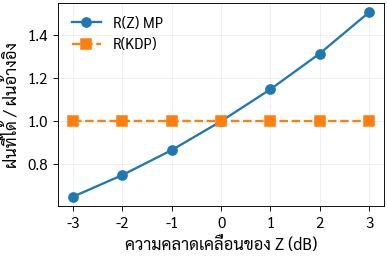

In [7]:
rows = []
for bias in [-3, -2, -1, 0, 1, 2, 3]:
    rz = qpe.r_from_z(out["Zc"] + bias)
    rows.append(dict(bias_db=bias, RZ_ratio=np.nanmean(rz[k]) / np.nanmean(out["R_MP"][k]),
                     RKDP_ratio=1.0))
sens = pd.DataFrame(rows)
fig, ax = pl.subplots(width="single", height_mm=60)
ax.plot(sens.bias_db, sens.RZ_ratio, "o-", label="R(Z) MP")
ax.plot(sens.bias_db, sens.RKDP_ratio, "s--", label="R(KDP)")
ax.set_xlabel("ความคลาดเคลื่อนของ Z (dB)"); ax.set_ylabel("ฝนที่ได้ / ฝนอ้างอิง"); ax.grid(alpha=0.3, lw=0.4); ax.legend()
pl.save(fig, "03_calibration_sensitivity"); plt.show()

---
## ✏️ แบบฝึกหัด

### แบบฝึกหัด 1 · 🟢 ป.ตรี

คำนวณความเข้มฝนที่ **40 dBZ** ด้วยสูตร Marshall–Palmer และ Rosenfeld (ใช้ `qpe.r_from_z`) ต่างกันกี่เท่า

In [8]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
r_mp40 = None; r_ros40 = None

In [9]:
#@title 🔑 เฉลยข้อ 1 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
r_mp40 = qpe.r_from_z(40, 200, 1.6); r_ros40 = qpe.r_from_z(40, 250, 1.2)
print(f"MP {r_mp40:.1f} mm/h, Rosenfeld {r_ros40:.1f} mm/h → ต่างกัน {r_ros40 / r_mp40:.1f} เท่า")
assert abs(r_mp40 - 11.5) < 0.2 and abs(r_ros40 - 21.6) < 0.2

MP 11.5 mm/h, Rosenfeld 21.6 mm/h → ต่างกัน 1.9 เท่า


### แบบฝึกหัด 2 · 🟢 ป.ตรี

ถ้า Z ของเรดาร์สูงเกินจริง **3 dB** ฝนจาก R(Z) จะสูงเกินจริงกี่เปอร์เซ็นต์ สำหรับ b = 1.6 และ b = 1.2 (แสดงสูตร)

In [10]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
err16 = None; err12 = None   # %

In [11]:
#@title 🔑 เฉลยข้อ 2 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
err16 = 100 * (10 ** (3 / (10 * 1.6)) - 1); err12 = 100 * (10 ** (3 / (10 * 1.2)) - 1)
print(f"b = 1.6: +{err16:.0f}%,  b = 1.2: +{err12:.0f}%  (R ∝ Z^(1/b) → ΔR/R = 10^(Δ/(10b)) − 1)")
assert round(err16) == 54 and round(err12) == 78

b = 1.6: +54%,  b = 1.2: +78%  (R ∝ Z^(1/b) → ΔR/R = 10^(Δ/(10b)) − 1)


### แบบฝึกหัด 3 · 🟢 ป.ตรี

ในพื้นที่ฝน (R_MP ≥ 0.5 มม./ชม.) มีกี่เปอร์เซ็นต์ที่ใช้ R(Z), R(A) และ R(KDP) ตามลำดับ

In [12]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
shares = None   # pd.Series

In [13]:
#@title 🔑 เฉลยข้อ 3 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
m = out["met"] & (out["R_MP"] >= 0.5)
shares = pd.Series(out["src"][m]).map({0: "R(Z)", 1: "R(A)", 2: "R(KDP)"}).value_counts(normalize=True) * 100
print(shares.round(1))

R(A)      50.0
R(Z)      45.8
R(KDP)     4.2
Name: proportion, dtype: float64


### แบบฝึกหัด 4 · 🔵 ป.โท / ส่วนขยาย

**ปรับค่า a, b ของ Z–R ให้เข้ากับฝนจริง** โดยถือ R(KDP) และ R(A) เป็นค่าอ้างอิงในจุดที่ใช้ได้ ใช้การถดถอยเชิงเส้นของ log Z กับ log R แล้วเปรียบเทียบกับ Marshall–Palmer ระวังอะไรบ้างในการตีความ

In [14]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
a_fit = None; b_fit = None

In [15]:
#@title 🔑 เฉลยข้อ 4 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
m = (out["src"] >= 1) & np.isfinite(out["Zc"])
Rref = np.where(out["src"] == 2, out["R_KDP"], out["R_A"])[m]; Zlin = 10 ** (out["Zc"][m] / 10)
ok = (Rref > 0.5) & np.isfinite(Rref)
b_fit, log_a = np.polyfit(np.log10(Rref[ok]), np.log10(Zlin[ok]), 1); a_fit = 10 ** log_a
print(f"Z = {a_fit:.0f} R^{b_fit:.2f}  (n = {ok.sum()})")
print("ค่า b < 1 ไม่สมจริงทางกายภาพ → สะท้อนว่า R(A) ถูกคำนวณจาก Z และ ΦDP ชุดเดียวกัน จึงไม่ใช่ค่าอ้างอิงที่อิสระ")
print("ข้อควรระวัง: R(A)/R(KDP) มีความคลาดเคลื่อนเอง, ตัวอย่างมาจาก 1 สแกน, Z ผ่านการแก้ attenuation ด้วย ΦDP เดียวกัน (ไม่อิสระ)")

Z = 175 R^0.97  (n = 2792)
ค่า b < 1 ไม่สมจริงทางกายภาพ → สะท้อนว่า R(A) ถูกคำนวณจาก Z และ ΦDP ชุดเดียวกัน จึงไม่ใช่ค่าอ้างอิงที่อิสระ
ข้อควรระวัง: R(A)/R(KDP) มีความคลาดเคลื่อนเอง, ตัวอย่างมาจาก 1 สแกน, Z ผ่านการแก้ attenuation ด้วย ΦDP เดียวกัน (ไม่อิสระ)


### แบบฝึกหัด 5 · 🔵 ป.โท / ส่วนขยาย

ใช้ DSD แบบ exponential แต่ **ให้ N₀ เปลี่ยน** (เช่น N₀ = 2000 และ 30000 m⁻³ mm⁻¹ แทน 8000) แล้วหา a, b ใหม่ ข้อนี้อธิบายความแตกต่างระหว่างฝน stratiform กับ convective อย่างไร

In [16]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
fits = None   # dict N0 -> (a, b)

In [17]:
#@title 🔑 เฉลยข้อ 5 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
fits = {}
for N0 in [2000, 8000, 30000]:
    rows = []
    for lam in np.linspace(1.5, 6, 20):
        N = N0 * np.exp(-lam * D)
        rows.append((trapz(N * D ** 6, D), 0.6e-3 * np.pi * trapz(N * D ** 3 * v, D)))
    Zs, Rs = np.array(rows).T
    b_, la = np.polyfit(np.log10(Rs), np.log10(Zs), 1); fits[N0] = (round(10 ** la), round(b_, 2))
print(fits)
print("N₀ มาก (เม็ดเล็กจำนวนมาก, ฝนเขตร้อน/ฝนอุ่น) → a เล็กลง: Z เดียวกันให้ฝนมากขึ้น")

{2000: (472, np.float64(1.5)), 8000: (237, np.float64(1.5)), 30000: (123, np.float64(1.5))}
N₀ มาก (เม็ดเล็กจำนวนมาก, ฝนเขตร้อน/ฝนอุ่น) → a เล็กลง: Z เดียวกันให้ฝนมากขึ้น


---
## 💡 คำถามชวนคิดและต่อยอด
- ค่าสัมประสิทธิ์ R(KDP) และ R(A) ในโค้ดมาจากวรรณกรรมต่างประเทศ ถ้ามีข้อมูล disdrometer ในภาคเหนือ จะหาค่าของไทยได้อย่างไร
- ทำไม R(A) จึงได้รับความนิยมใน MeteoSwiss/NOAA (Ryzhkov et al. 2014) มากกว่า R(KDP) ในฝนปานกลาง
- ลูกเห็บทำให้ Z สูงมากแต่ KDP ไม่สูง เกณฑ์ 55 dBZ (hail cap) ในโค้ดช่วยอะไร และทำไม blended จึงทนต่อลูกเห็บกว่า
- 🔵 ลองเพิ่มตัวประมาณ $R(Z, Z_{DR})$ หรือ $R(K_{DP}, Z_{DR})$ แล้วเปรียบเทียบ

## 📚 อ้างอิง
- Marshall, J.S. & Palmer, W.M. (1948). The distribution of raindrops with size. *J. Meteor.* 5:165–166.
- Rosenfeld, D. et al. (1993). General probability-matched relations between radar reflectivity and rain rate. *J. Appl. Meteor.* 32:50–72.
- Ryzhkov, A. et al. (2014). Potential utilization of specific attenuation for rainfall estimation. *J. Appl. Meteor. Climatol.* 53:2290–2306.
- Giangrande, S.E. & Ryzhkov, A.V. (2008). Estimation of rainfall based on the results of polarimetric echo classification. *J. Appl. Meteor. Climatol.* 47:2445–2462.
- Atlas, D. & Ulbrich, C.W. (1977). Path- and area-integrated rainfall measurement by microwave attenuation. *J. Appl. Meteor.* 16:1322–1331.

In [18]:
#@title 💾 บันทึกผลลัพธ์ขึ้น GitHub (fork ของคุณเอง) { display-mode: "form" }
#@markdown ใส่รหัสนิสิต แล้วรันเซลล์นี้ (ต้องตั้ง Colab Secrets `GITHUB_USER` และ `GITHUB_TOKEN` ก่อน — ดูขั้นตอนใน notebook 00)
STUDENT_ID = ""  #@param {type:"string"}
if STUDENT_ID:
    colab.save_to_fork(STUDENT_ID, message="NB03: results")
else:
    print("ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)")

ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)
